<a href="https://colab.research.google.com/github/Phoenix007-sys/Case-Exercise-1/blob/main/Case_Exercise_1_Design_Envelope_Construction_and_Visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Implement the pressure_temperature_envelope() function from Section 2.2.2 with full documentation and error handling.

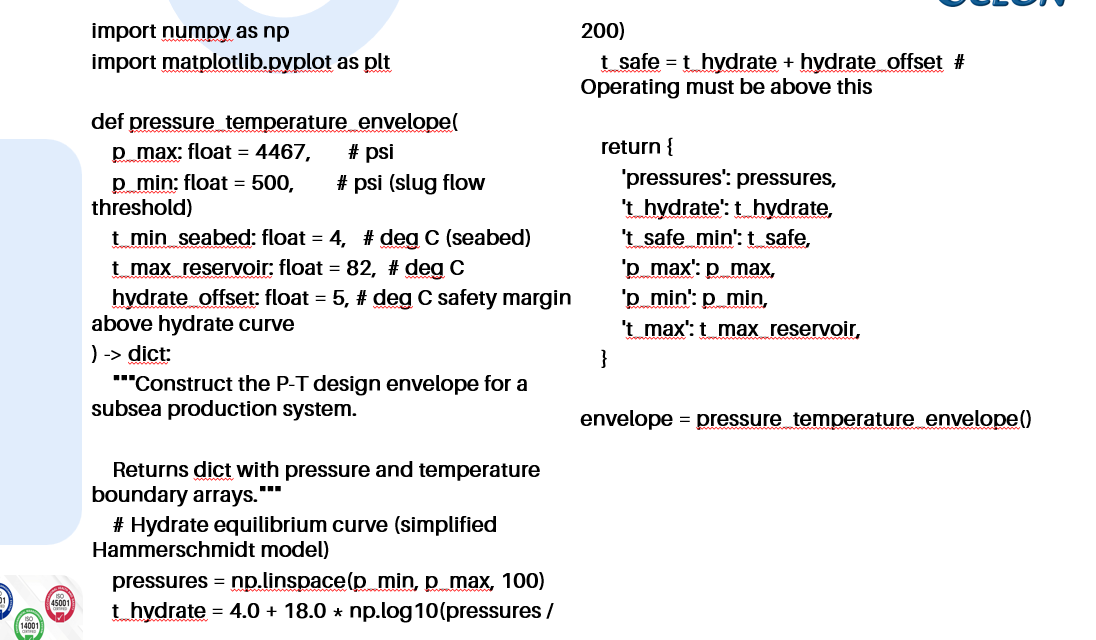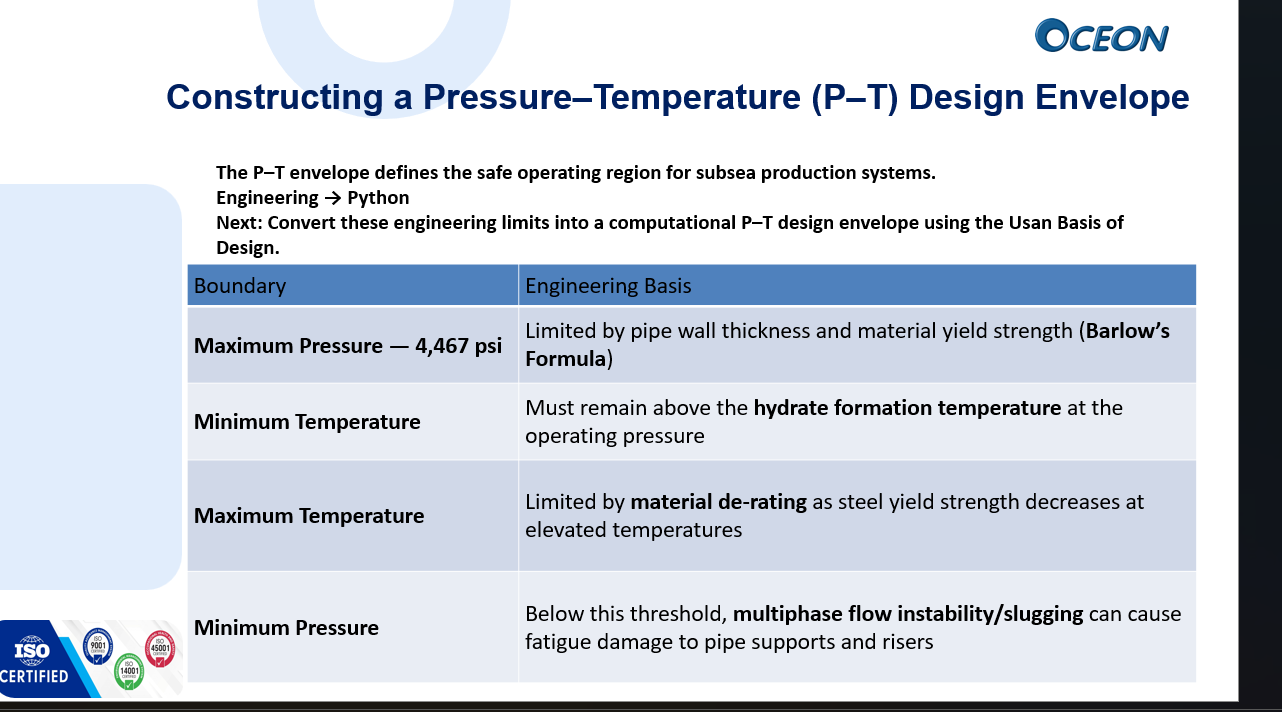

In [ ]:
import numpy as np


def pressure_temperature_envelope(
    p_max: float = 4467,          # psi
    p_min: float = 500,           # psi (slug flow threshold)
    t_min_seabed: float = 4,      # deg C (seabed)
    t_max_reservoir: float = 82,  # deg C
    hydrate_offset: float = 5,    # deg C safety margin above hydrate curve
) -> dict:
    """Construct the P-T design envelope for a subsea production system.

    The envelope defines the safe operating region bounded by:
      - p_max: pipe wall/material pressure limit (Barlow's Formula)
      - p_min: multiphase flow stability limit (below this, slugging risk)
      - t_min_seabed: must stay above hydrate formation temp + safety margin
      - t_max_reservoir: material de-rating limit at elevated temperature

    Parameters
    ----------
    p_max : float
        Maximum allowable pressure (psi). Must be positive and > p_min.
    p_min : float
        Minimum allowable pressure (psi) before slug flow instability.
        Must be positive and < p_max.
    t_min_seabed : float
        Seabed/ambient minimum temperature (deg C).
    t_max_reservoir : float
        Maximum reservoir/operating temperature (deg C).
        Must be greater than t_min_seabed.
    hydrate_offset : float
        Safety margin (deg C) added above the hydrate equilibrium curve
        to define the safe operating temperature. Must be >= 0.

    Returns
    -------
    dict
        {
            'pressures':  np.ndarray — pressure sweep (psi)
            't_hydrate':  np.ndarray — hydrate formation temp at each pressure (deg C)
            't_safe_min': np.ndarray — minimum safe operating temp at each pressure (deg C)
            'p_max':      float — upper pressure boundary
            'p_min':      float — lower pressure boundary
            't_max':      float — upper temperature boundary
        }

    Raises
    ------
    ValueError
        If any input is non-physical (e.g. p_min <= 0, p_max <= p_min,
        t_max_reservoir <= t_min_seabed, hydrate_offset < 0).
    """
    # --- Validate inputs before doing any engineering calculation ---
    if p_min <= 0:
        raise ValueError(f"p_min must be positive, got {p_min}")
    if p_max <= p_min:
        raise ValueError(f"p_max ({p_max}) must be greater than p_min ({p_min})")
    if t_max_reservoir <= t_min_seabed:
        raise ValueError(
            f"t_max_reservoir ({t_max_reservoir}) must exceed "
            f"t_min_seabed ({t_min_seabed})"
        )
    if hydrate_offset < 0:
        raise ValueError(f"hydrate_offset cannot be negative, got {hydrate_offset}")

    # Hydrate equilibrium curve (simplified Hammerschmidt model)
    pressures = np.linspace(p_min, p_max, 200)
    t_hydrate = 4.0 + 18.0 * np.log10(pressures / 200)
    t_safe = t_hydrate + hydrate_offset  # Operating must be above this

    return {
        'pressures': pressures,
        't_hydrate': t_hydrate,
        't_safe_min': t_safe,
        'p_max': p_max,
        'p_min': p_min,
        't_max': t_max_reservoir,
    }


envelope = pressure_temperature_envelope()

Question 2

Create a 2D P-T envelope plot showing the safe operating region, hydrate curve, WAT line, and MAOP boundary. Plot the six jumper operating points from Table 2.9

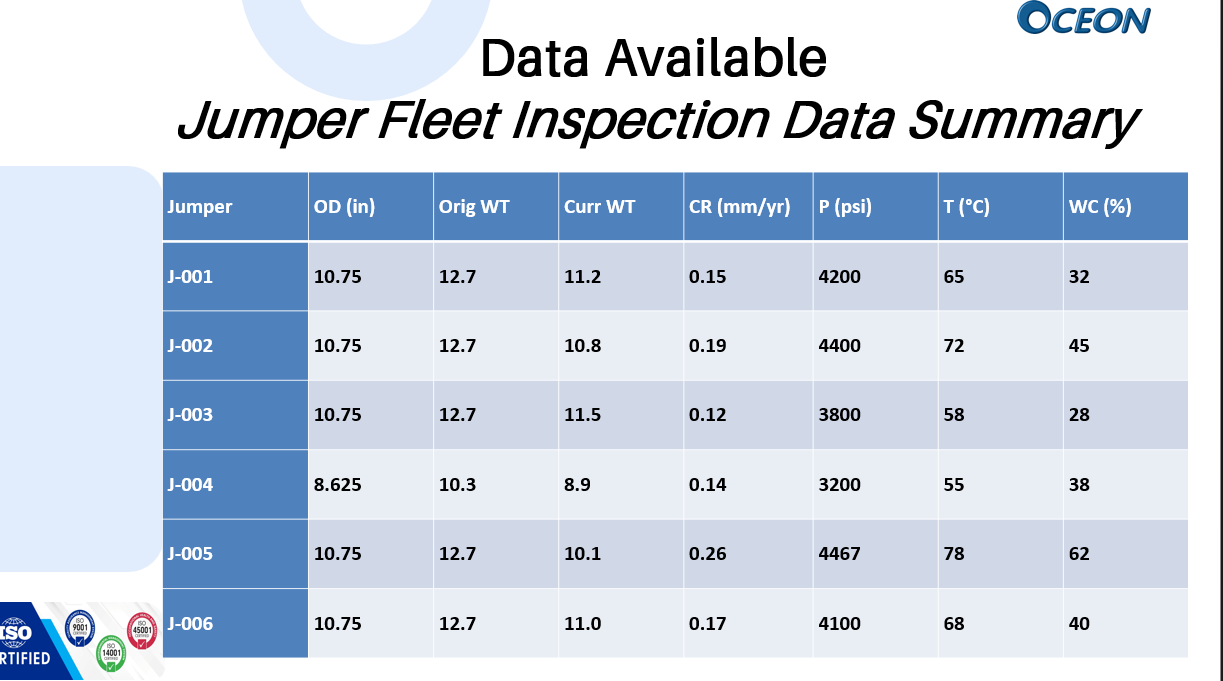)

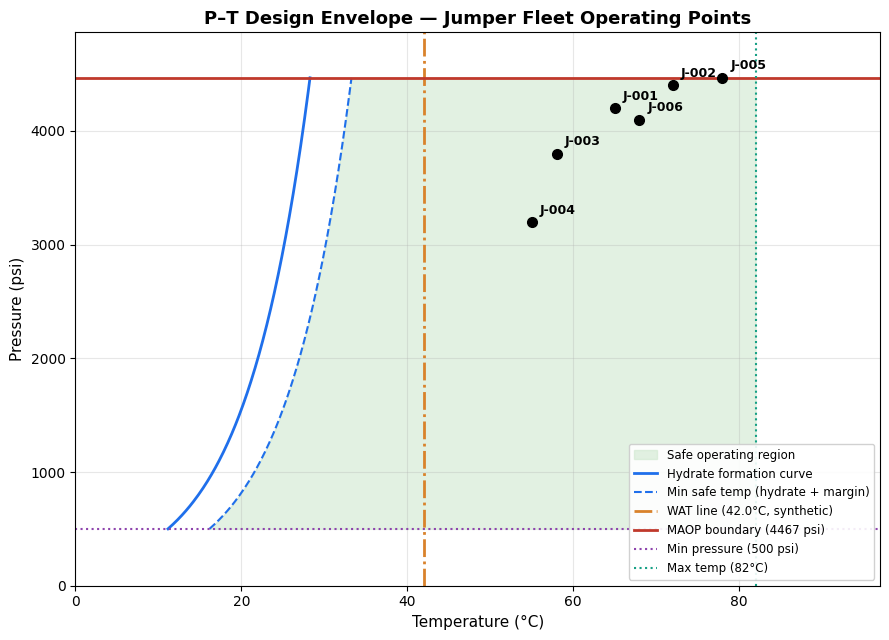

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def pressure_temperature_envelope(
    p_max: float = 4467,          # psi
    p_min: float = 500,           # psi (slug flow threshold)
    t_min_seabed: float = 4,      # deg C (seabed)
    t_max_reservoir: float = 82,  # deg C
    hydrate_offset: float = 5,    # deg C safety margin above hydrate curve
) -> dict:
    """Construct the P-T design envelope for a subsea production system."""
    if p_min <= 0:
        raise ValueError(f"p_min must be positive, got {p_min}")
    if p_max <= p_min:
        raise ValueError(f"p_max ({p_max}) must be greater than p_min ({p_min})")
    if t_max_reservoir <= t_min_seabed:
        raise ValueError(
            f"t_max_reservoir ({t_max_reservoir}) must exceed "
            f"t_min_seabed ({t_min_seabed})"
        )
    if hydrate_offset < 0:
        raise ValueError(f"hydrate_offset cannot be negative, got {hydrate_offset}")

    pressures = np.linspace(p_min, p_max, 200)
    t_hydrate = 4.0 + 18.0 * np.log10(pressures / 200)
    t_safe = t_hydrate + hydrate_offset

    return {
        'pressures': pressures,
        't_hydrate': t_hydrate,
        't_safe_min': t_safe,
        'p_max': p_max,
        'p_min': p_min,
        't_max': t_max_reservoir,
    }


def plot_pt_envelope(envelope: dict, jumpers: list, wat_temp: float = 42.0) -> None:
    """Plot the P-T design envelope with hydrate curve, WAT line, MAOP boundary,
    and jumper operating points overlaid.

    Parameters
    ----------
    envelope : dict
        Output of pressure_temperature_envelope().
    jumpers : list of dict
        Each dict: {'id': str, 'p': float (psi), 't': float (deg C)}.
    wat_temp : float
        Wax Appearance Temperature (deg C) — synthetic value, not measured.
    """
    p = envelope['pressures']
    t_hydrate = envelope['t_hydrate']
    t_safe = envelope['t_safe_min']
    p_max = envelope['p_max']
    p_min = envelope['p_min']
    t_max = envelope['t_max']

    fig, ax = plt.subplots(figsize=(9, 6.5))

    ax.fill_betweenx(p, t_safe, t_max, where=(t_safe < t_max),
                      color='#cfe8cf', alpha=0.6, label='Safe operating region')
    ax.plot(t_hydrate, p, color='#1f6feb', lw=2, label='Hydrate formation curve')
    ax.plot(t_safe, p, color='#1f6feb', lw=1.5, ls='--',
            label='Min safe temp (hydrate + margin)')
    ax.axvline(wat_temp, color='#d9822b', lw=2, ls='-.',
               label=f'WAT line ({wat_temp}°C, synthetic)')
    ax.axhline(p_max, color='#c0392b', lw=2, label=f'MAOP boundary ({p_max:.0f} psi)')
    ax.axhline(p_min, color='#8e44ad', lw=1.5, ls=':', label=f'Min pressure ({p_min:.0f} psi)')
    ax.axvline(t_max, color='#16a085', lw=1.5, ls=':', label=f'Max temp ({t_max:.0f}°C)')

    for j in jumpers:
        ax.plot(j['t'], j['p'], 'ko', ms=7, zorder=5)
        ax.annotate(j['id'], (j['t'], j['p']), textcoords="offset points",
                    xytext=(6, 6), fontsize=9, fontweight='bold')

    ax.set_xlabel('Temperature (°C)', fontsize=11)
    ax.set_ylabel('Pressure (psi)', fontsize=11)
    ax.set_title('P–T Design Envelope — Jumper Fleet Operating Points', fontsize=13, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8.5, framealpha=0.9)
    ax.grid(alpha=0.3)
    ax.set_xlim(0, max(t_max, wat_temp) + 15)
    ax.set_ylim(0, p_max + 400)

    plt.tight_layout()
    plt.show()


# Table 2.9 — Jumper Fleet Inspection Data Summary
jumpers = [
    {'id': 'J-001', 'p': 4200, 't': 65},
    {'id': 'J-002', 'p': 4400, 't': 72},
    {'id': 'J-003', 'p': 3800, 't': 58},
    {'id': 'J-004', 'p': 3200, 't': 55},
    {'id': 'J-005', 'p': 4467, 't': 78},
    {'id': 'J-006', 'p': 4100, 't': 68},
]

envelope = pressure_temperature_envelope()
plot_pt_envelope(envelope, jumpers)

Question 3

Extend to a 3-parameter envelope (P-T-flow rate) and create a 3D scatter plot showing operating points coloured by envelope status.


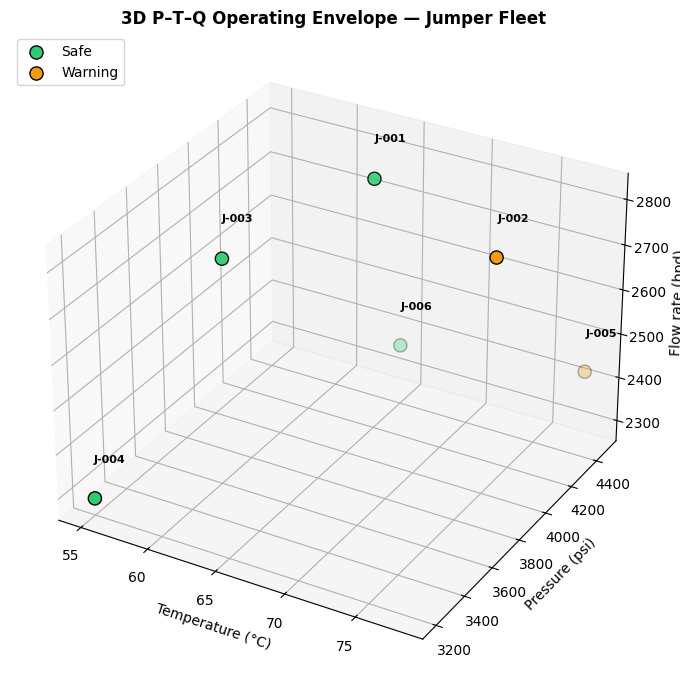

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (enables 3D projection)


def pressure_temperature_flow_envelope(
    p_max: float = 4467,          # psi
    p_min: float = 500,           # psi (slug flow threshold)
    t_min_seabed: float = 4,      # deg C (seabed)
    t_max_reservoir: float = 82,  # deg C
    hydrate_offset: float = 5,    # deg C safety margin above hydrate curve
    q_min: float = 1200,          # bpd (minimum flow to avoid liquid hold-up / slugging)
    q_max: float = 4800,          # bpd (erosional velocity limit, API RP 14E style)
) -> dict:
    """Construct the 3-parameter P-T-Q design envelope for a subsea production system.

    Extends the 2D P-T envelope with a flow-rate (Q) axis bounded by:
      - q_min: minimum flow to prevent liquid hold-up / slugging in the line
      - q_max: maximum flow before erosional velocity limits are exceeded

    Parameters
    ----------
    p_max, p_min : float
        Pressure boundaries (psi), as in the 2D envelope.
    t_min_seabed, t_max_reservoir, hydrate_offset : float
        Temperature boundaries and hydrate margin (deg C), as in the 2D envelope.
    q_min, q_max : float
        Flow-rate boundaries (bpd).

    Returns
    -------
    dict
        2D envelope fields plus 'q_min' and 'q_max'.

    Raises
    ------
    ValueError
        On non-physical inputs, including q_min <= 0 or q_max <= q_min.
    """
    if p_min <= 0:
        raise ValueError(f"p_min must be positive, got {p_min}")
    if p_max <= p_min:
        raise ValueError(f"p_max ({p_max}) must be greater than p_min ({p_min})")
    if t_max_reservoir <= t_min_seabed:
        raise ValueError(
            f"t_max_reservoir ({t_max_reservoir}) must exceed t_min_seabed ({t_min_seabed})"
        )
    if hydrate_offset < 0:
        raise ValueError(f"hydrate_offset cannot be negative, got {hydrate_offset}")
    if q_min <= 0:
        raise ValueError(f"q_min must be positive, got {q_min}")
    if q_max <= q_min:
        raise ValueError(f"q_max ({q_max}) must be greater than q_min ({q_min})")

    pressures = np.linspace(p_min, p_max, 200)
    t_hydrate = 4.0 + 18.0 * np.log10(pressures / 200)
    t_safe = t_hydrate + hydrate_offset

    return {
        'pressures': pressures,
        't_hydrate': t_hydrate,
        't_safe_min': t_safe,
        'p_max': p_max,
        'p_min': p_min,
        't_max': t_max_reservoir,
        'q_min': q_min,
        'q_max': q_max,
    }


def hydrate_temp(p: float) -> float:
    """Hydrate formation temperature (deg C) at a given pressure (psi)."""
    return 4.0 + 18.0 * np.log10(p / 200)


def classify_status(p: float, t: float, q: float, envelope: dict, margin: float = 0.05) -> str:
    """Classify an operating point as 'Safe', 'Warning', or 'Violation'.

    'Warning' means inside the envelope but within `margin` (fractional) of
    any boundary. 'Violation' means at least one boundary is breached.
    """
    t_min_safe = hydrate_temp(p) + 5  # hydrate curve + fixed safety offset

    checks = {
        'p_low': (p - envelope['p_min']) / (envelope['p_max'] - envelope['p_min']),
        'p_high': (envelope['p_max'] - p) / (envelope['p_max'] - envelope['p_min']),
        't_low': (t - t_min_safe) / (envelope['t_max'] - t_min_safe),
        't_high': (envelope['t_max'] - t) / (envelope['t_max'] - t_min_safe),
        'q_low': (q - envelope['q_min']) / (envelope['q_max'] - envelope['q_min']),
        'q_high': (envelope['q_max'] - q) / (envelope['q_max'] - envelope['q_min']),
    }

    if any(v < 0 for v in checks.values()):
        return 'Violation'
    if any(v < margin for v in checks.values()):
        return 'Warning'
    return 'Safe'


def generate_synthetic_flow(jumpers: list, seed: int = 42) -> list:
    """Generate synthetic flow rates (bpd) correlated with each jumper's
    pressure and water cut, since Table 2.9 has no flow column.

    Higher pressure -> higher flow; higher water cut -> somewhat lower oil
    flow (more water fraction displacing oil throughput). Fixed seed keeps
    this reproducible.
    """
    rng = np.random.default_rng(seed)
    for j in jumpers:
        base = 2600 + 0.55 * (j['p'] - 4000) - 9 * (j['wc'] - 40)
        noise = rng.normal(0, 120)
        j['q'] = round(base + noise, 1)
    return jumpers


# Table 2.9 — Jumper Fleet Inspection Data Summary
jumpers = [
    {'id': 'J-001', 'p': 4200, 't': 65, 'wc': 32},
    {'id': 'J-002', 'p': 4400, 't': 72, 'wc': 45},
    {'id': 'J-003', 'p': 3800, 't': 58, 'wc': 28},
    {'id': 'J-004', 'p': 3200, 't': 55, 'wc': 38},
    {'id': 'J-005', 'p': 4467, 't': 78, 'wc': 62},
    {'id': 'J-006', 'p': 4100, 't': 68, 'wc': 40},
]

jumpers = generate_synthetic_flow(jumpers)
envelope = pressure_temperature_flow_envelope()

for j in jumpers:
    j['status'] = classify_status(j['p'], j['t'], j['q'], envelope)

status_colors = {'Safe': '#2ecc71', 'Warning': '#f39c12', 'Violation': '#e74c3c'}

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

for status in status_colors:
    pts = [j for j in jumpers if j['status'] == status]
    if pts:
        ax.scatter(
            [j['t'] for j in pts], [j['p'] for j in pts], [j['q'] for j in pts],
            c=status_colors[status], s=90, label=status, edgecolors='k', depthshade=True,
        )
for j in jumpers:
    ax.text(j['t'], j['p'], j['q'] + 80, j['id'], fontsize=8, fontweight='bold')

ax.set_xlabel('Temperature (°C)')
ax.set_ylabel('Pressure (psi)')
ax.set_zlabel('Flow rate (bpd)')
ax.set_title('3D P–T–Q Operating Envelope — Jumper Fleet', fontweight='bold')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

Question 4

Write a function that takes a DataFrame of operating data and returns the percentage of time each parameter was within the design envelope.


In [4]:
import numpy as np
import pandas as pd


def hydrate_temp(p):
    """Hydrate formation temperature (deg C) at pressure p (psi). Vectorized."""
    return 4.0 + 18.0 * np.log10(np.asarray(p) / 200)


def compute_envelope_compliance(
    df: pd.DataFrame,
    envelope: dict,
    p_col: str = 'p',
    t_col: str = 't',
    q_col: str = 'q',
    hydrate_offset: float = 5,
) -> dict:
    """Compute the percentage of time each parameter stayed within its
    design-envelope bound, from a time-series DataFrame of operating data.

    Parameters
    ----------
    df : pd.DataFrame
        One row per time sample, containing pressure, temperature and
        flow-rate columns.
    envelope : dict
        Output of pressure_temperature_flow_envelope() — supplies p_min,
        p_max, t_max, q_min, q_max.
    p_col, t_col, q_col : str
        Column names for pressure (psi), temperature (deg C), flow rate (bpd).
    hydrate_offset : float
        Safety margin (deg C) above the hydrate curve — must match the value
        used when the envelope was built.

    Returns
    -------
    dict
        {
            'pressure_pct':    % of samples with p_min <= P <= p_max
            'temperature_pct': % of samples with (hydrate curve + offset) <= T <= t_max
            'flow_pct':        % of samples with q_min <= Q <= q_max
            'overall_pct':     % of samples where all three held simultaneously
            'n_samples':       row count evaluated (rows with missing values dropped)
        }

    Raises
    ------
    ValueError
        If df is empty, a required column is missing or non-numeric, or no
        complete rows remain after dropping missing values.
    """
    if df.empty:
        raise ValueError("df is empty — no operating data to evaluate")

    required = {p_col, t_col, q_col}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"df is missing required column(s): {sorted(missing)}")

    data = df[[p_col, t_col, q_col]].copy()
    for col in (p_col, t_col, q_col):
        if not pd.api.types.is_numeric_dtype(data[col]):
            raise ValueError(f"column '{col}' must be numeric")

    data = data.dropna()
    n_samples = len(data)
    if n_samples == 0:
        raise ValueError("no complete rows remain after dropping missing values")

    p, t, q = data[p_col].to_numpy(), data[t_col].to_numpy(), data[q_col].to_numpy()

    p_ok = (p >= envelope['p_min']) & (p <= envelope['p_max'])
    t_min_safe = hydrate_temp(p) + hydrate_offset  # hydrate boundary varies with P
    t_ok = (t >= t_min_safe) & (t <= envelope['t_max'])
    q_ok = (q >= envelope['q_min']) & (q <= envelope['q_max'])

    return {
        'pressure_pct': round(float(p_ok.mean()) * 100, 2),
        'temperature_pct': round(float(t_ok.mean()) * 100, 2),
        'flow_pct': round(float(q_ok.mean()) * 100, 2),
        'overall_pct': round(float((p_ok & t_ok & q_ok).mean()) * 100, 2),
        'n_samples': int(n_samples),
    }